In [3]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv(r"C:\Users\Aditya maurya\AIS.csv")
print("Shape:", df.shape)
df.head()

C:\Users\Aditya maurya\AppData\Local\Temp\ipykernel_19980\2492787693.py:1: DtypeWarning: Columns (0: IMO) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\Aditya maurya\AIS.csv")


Shape: (9444308, 17)


,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading,VesselName,IMO,CallSign,VesselType,Status,Length,Width,Draft,Cargo,TransceiverClass
0,367000140,2024-03-21T00:01:05,40.64803,-74.06623,11.6,252.0,260.0,SAMUEL I NEWHOUSE,IMO7702774,WYR3371,69.0,0.0,95.0,22.0,5.0,69.0,A
1,367000140,2024-03-21T00:00:00,40.64945,-74.06158,13.6,232.0,238.0,SAMUEL I NEWHOUSE,IMO7702774,WYR3371,69.0,0.0,95.0,22.0,5.0,69.0,A
2,367000140,2024-03-16T00:00:00,40.64367,-74.07133,0.0,24.0,255.0,SAMUEL I NEWHOUSE,IMO7702774,WYR3371,69.0,0.0,95.0,22.0,5.0,69.0,A
3,367000140,2024-03-16T00:01:01,40.64383,-74.07103,0.0,334.0,75.0,SAMUEL I NEWHOUSE,IMO7702774,WYR3371,69.0,0.0,95.0,22.0,5.0,69.0,A
4,367000140,2024-03-26T00:00:01,40.69995,-74.01225,0.0,56.0,164.0,SAMUEL I NEWHOUSE,IMO7702774,WYR3371,69.0,0.0,95.0,22.0,5.0,69.0,A


In [5]:
print("Unique vessels (MMSI):", df["MMSI"].nunique())
print("Date range:", df["BaseDateTime"].min(), "to", df["BaseDateTime"].max())
print("\nColumn data types:")
print(df.dtypes)

Unique vessels (MMSI): 1415
Date range: 2024-03-02T00:00:00 to 2024-04-28T23:59:59

Column data types:
MMSI                  int64
BaseDateTime            str
LAT                 float64
LON                 float64
SOG                 float64
COG                 float64
Heading             float64
VesselName              str
IMO                     str
CallSign                str
VesselType          float64
Status              float64
Length              float64
Width               float64
Draft               float64
Cargo               float64
TransceiverClass        str
dtype: object


In [6]:
# Convert timestamp to real datetime type
df["BaseDateTime"] = pd.to_datetime(df["BaseDateTime"])

# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
MMSI                      0
BaseDateTime              0
LAT                       0
LON                       0
SOG                       0
COG                       0
Heading                   0
VesselName             2906
IMO                 3313079
CallSign             111472
VesselType               51
Status               262730
Length                14700
Width                 21632
Draft                248805
Cargo                248805
TransceiverClass          0
dtype: int64


In [7]:
print(df[["LAT", "LON", "SOG", "COG", "Heading"]].describe())

                LAT           LON           SOG           COG       Heading
count  9.444308e+06  9.444308e+06  9.444308e+06  9.444308e+06  9.444308e+06
mean   4.063231e+01 -7.409254e+01  2.559497e+00  2.095716e+02  2.872360e+02
std    7.150244e-02  7.932320e-02  7.027492e+00  1.101489e+02  1.736579e+02
min    4.040741e+01 -7.427906e+01  0.000000e+00  0.000000e+00  0.000000e+00
25%    4.063410e+01 -7.415040e+01  0.000000e+00  1.202000e+02  1.540000e+02
50%    4.064477e+01 -7.407973e+01  0.000000e+00  2.262000e+02  2.670000e+02
75%    4.068100e+01 -7.403287e+01  9.000000e-01  3.013000e+02  5.110000e+02
max    4.070503e+01 -7.385241e+01  1.023000e+02  3.600000e+02  5.110000e+02


In [8]:


# Replace known AIS sentinel/placeholder values with NaN
df["SOG"] = df["SOG"].replace(102.3, np.nan)
df["Heading"] = df["Heading"].replace(511.0, np.nan)

# Re-check stats
print(df[["SOG", "Heading"]].describe())
print("\nMissing after cleanup:")
print(df[["SOG", "Heading"]].isnull().sum())

                SOG       Heading
count  9.423319e+06  6.478662e+06
mean   2.337340e+00  1.848066e+02
std    5.223818e+00  1.027125e+02
min    0.000000e+00  0.000000e+00
25%    0.000000e+00  9.800000e+01
50%    0.000000e+00  1.990000e+02
75%    8.000000e-01  2.750000e+02
max    1.022000e+02  3.590000e+02

Missing after cleanup:
SOG          20989
Heading    2965646
dtype: int64


In [9]:
# Look at the highest SOG values to spot any remaining junk
print(df["SOG"].sort_values(ascending=False).head(30))


1048713    102.2
1048725    102.2
4695069    102.2
816399     102.2
3047729    102.2
1048718    102.2
2374964    102.2
1048697     97.0
6997946     85.1
2112453     84.9
9404985     84.9
1048682     83.5
6997940     80.7
6997938     75.2
5172784     73.2
4593328     72.7
6997876     72.5
4593448     71.6
5171565     67.8
4858909     65.4
5171567     63.8
7143953     61.2
4226875     59.9
9437075     59.4
1208136     57.7
6997942     55.3
9437229     54.3
1061717     52.8
5172548     51.8
6694745     49.0
Name: SOG, dtype: float64


In [10]:
# Remove remaining sentinel cluster and implausible speeds
df.loc[df["SOG"] == 102.2, "SOG"] = np.nan
df.loc[df["SOG"] > 50, "SOG"] = np.nan  # cap: no harbor vessel realistically exceeds this

print(df["SOG"].describe())
print("\nMissing SOG now:", df["SOG"].isnull().sum())

count    9.423290e+06
mean     2.337109e+00
std      5.222072e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      8.000000e-01
max      4.900000e+01
Name: SOG, dtype: float64

Missing SOG now: 21018


In [11]:
# Sort so each vessel's records are in chronological order
df = df.sort_values(["MMSI", "BaseDateTime"]).reset_index(drop=True)

# Quick check: look at one vessel's trajectory
sample_mmsi = df["MMSI"].iloc[0]
sample_trajectory = df[df["MMSI"] == sample_mmsi]
print(f"Vessel {sample_mmsi} has {len(sample_trajectory)} position reports")
sample_trajectory[["BaseDateTime", "LAT", "LON", "SOG", "COG"]].head(10)

Vessel 205206370 has 32 position reports


,BaseDateTime,LAT,LON,SOG,COG
0,2024-04-28 23:11:53,40.40920,-73.93105,6.4,337.4
1,2024-04-28 23:13:52,40.41241,-73.93293,6.6,335.7
2,2024-04-28 23:15:22,40.41491,-73.93443,7.1,334.7
3,2024-04-28 23:16:52,40.41737,-73.93594,6.6,336.4
4,2024-04-28 23:17:53,40.41905,-73.93691,6.4,338.1
5,2024-04-28 23:19:22,40.42151,-73.93836,6.2,337.0
6,2024-04-28 23:20:52,40.42397,-73.93987,7.1,333.9
7,2024-04-28 23:21:54,40.42561,-73.94092,6.5,332.0
8,2024-04-28 23:23:22,40.42803,-73.94251,6.6,330.7
9,2024-04-28 23:24:52,40.43047,-73.94415,6.7,332.4


In [12]:


def haversine_distance(lat1, lon1, lat2, lon2):
    """Calculate distance in nautical miles between two lat/lon points."""
    R = 3440.065  # Earth's radius in nautical miles
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

In [13]:
# Shift LAT/LON/time within each vessel group to get "previous reading" values
df["prev_LAT"] = df.groupby("MMSI")["LAT"].shift(1)
df["prev_LON"] = df.groupby("MMSI")["LON"].shift(1)
df["prev_time"] = df.groupby("MMSI")["BaseDateTime"].shift(1)
df["prev_SOG"] = df.groupby("MMSI")["SOG"].shift(1)
df["prev_COG"] = df.groupby("MMSI")["COG"].shift(1)

df[["MMSI", "BaseDateTime", "LAT", "prev_LAT", "prev_time"]].head(10)

,MMSI,BaseDateTime,LAT,prev_LAT,prev_time
0,205206370,2024-04-28 23:11:53,40.40920,NaN,NaT
1,205206370,2024-04-28 23:13:52,40.41241,40.40920,2024-04-28 23:11:53
2,205206370,2024-04-28 23:15:22,40.41491,40.41241,2024-04-28 23:13:52
3,205206370,2024-04-28 23:16:52,40.41737,40.41491,2024-04-28 23:15:22
4,205206370,2024-04-28 23:17:53,40.41905,40.41737,2024-04-28 23:16:52
5,205206370,2024-04-28 23:19:22,40.42151,40.41905,2024-04-28 23:17:53
6,205206370,2024-04-28 23:20:52,40.42397,40.42151,2024-04-28 23:19:22
7,205206370,2024-04-28 23:21:54,40.42561,40.42397,2024-04-28 23:20:52
8,205206370,2024-04-28 23:23:22,40.42803,40.42561,2024-04-28 23:21:54
9,205206370,2024-04-28 23:24:52,40.43047,40.42803,2024-04-28 23:23:22


In [14]:
# Time gap in minutes since previous reading
df["time_gap_min"] = (df["BaseDateTime"] - df["prev_time"]).dt.total_seconds() / 60

# Distance moved since previous reading (nautical miles)
df["distance_nm"] = haversine_distance(df["prev_LAT"], df["prev_LON"], df["LAT"], df["LON"])

# Speed change since previous reading
df["speed_change"] = df["SOG"] - df["prev_SOG"]

# Course change since previous reading (handling the 0-360 wraparound)
raw_course_diff = df["COG"] - df["prev_COG"]
df["course_change"] = raw_course_diff.abs().clip(upper=360) 
df["course_change"] = np.minimum(df["course_change"], 360 - df["course_change"])

df[["MMSI", "BaseDateTime", "time_gap_min", "distance_nm", "speed_change", "course_change"]].head(10)

,MMSI,BaseDateTime,time_gap_min,distance_nm,speed_change,course_change
0,205206370,2024-04-28 23:11:53,NaN,NaN,NaN,NaN
1,205206370,2024-04-28 23:13:52,1.983333,0.211025,0.2,1.7
2,205206370,2024-04-28 23:15:22,1.500000,0.165022,0.5,1.0
3,205206370,2024-04-28 23:16:52,1.500000,0.163033,-0.5,1.7
4,205206370,2024-04-28 23:17:53,1.016667,0.110183,-0.2,1.7
5,205206370,2024-04-28 23:19:22,1.483333,0.161889,-0.2,1.1
6,205206370,2024-04-28 23:20:52,1.500000,0.163030,0.9,3.1
7,205206370,2024-04-28 23:21:54,1.033333,0.109539,-0.6,1.9
8,205206370,2024-04-28 23:23:22,1.466667,0.162458,0.1,1.3
9,205206370,2024-04-28 23:24:52,1.500000,0.164560,0.1,1.7


In [15]:
print(df[["time_gap_min", "distance_nm", "speed_change", "course_change"]].describe())

       time_gap_min   distance_nm  speed_change  course_change
count  9.442893e+06  9.442893e+06  9.416777e+06   9.442893e+06
mean   4.328220e+00  4.460855e-02 -6.783637e-05   2.351508e+01
std    2.031595e+02  1.154662e-01  1.642817e+00   4.217387e+01
min    0.000000e+00  0.000000e+00 -4.440000e+01   0.000000e+00
25%    1.150000e+00  6.004046e-04  0.000000e+00   0.000000e+00
50%    1.166667e+00  1.495152e-03  0.000000e+00   3.200000e+00
75%    1.200000e+00  2.305834e-02  0.000000e+00   2.290000e+01
max    7.810385e+04  1.901380e+01  4.650000e+01   1.800000e+02


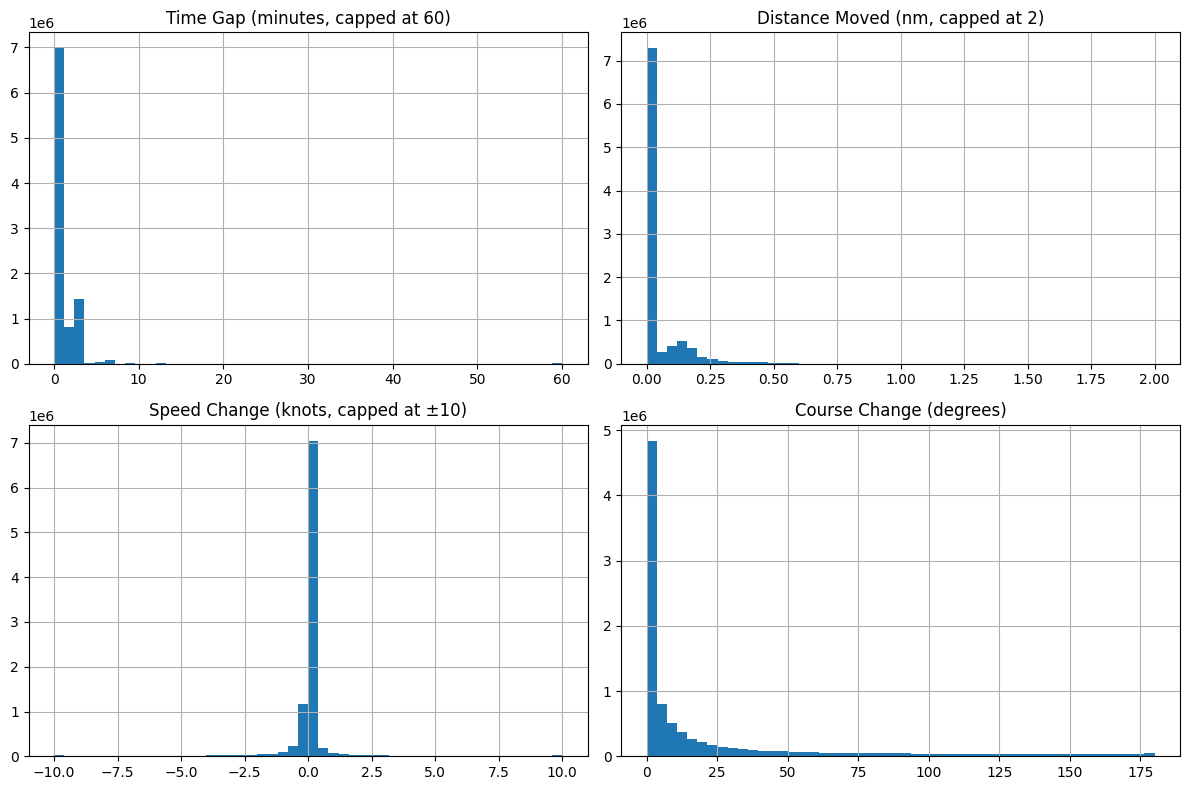

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df["time_gap_min"].clip(upper=60).hist(bins=50, ax=axes[0,0])
axes[0,0].set_title("Time Gap (minutes, capped at 60)")

df["distance_nm"].clip(upper=2).hist(bins=50, ax=axes[0,1])
axes[0,1].set_title("Distance Moved (nm, capped at 2)")

df["speed_change"].clip(lower=-10, upper=10).hist(bins=50, ax=axes[1,0])
axes[1,0].set_title("Speed Change (knots, capped at ±10)")

df["course_change"].hist(bins=50, ax=axes[1,1])
axes[1,1].set_title("Course Change (degrees)")

plt.tight_layout()
plt.show()

In [17]:
# Find the row with the largest time gap
biggest_gap_idx = df["time_gap_min"].idxmax()
mmsi_with_gap = df.loc[biggest_gap_idx, "MMSI"]

print("Vessel with biggest time gap:", mmsi_with_gap)
print("\nFull trajectory around that gap:")
df[df["MMSI"] == mmsi_with_gap][["BaseDateTime", "LAT", "LON", "SOG", "time_gap_min", "distance_nm"]]

Vessel with biggest time gap: 366990620

Full trajectory around that gap:


,BaseDateTime,LAT,LON,SOG,time_gap_min,distance_nm
1963826,2024-03-02 00:00:06,40.69330,-74.01497,0.0,NaN,NaN
1963827,2024-03-02 00:01:17,40.69409,-74.01467,2.1,1.183333,0.049359
1963828,2024-03-02 00:02:27,40.69464,-74.01275,7.0,1.166667,0.093433
1963829,2024-03-02 00:03:36,40.69624,-74.01005,8.8,1.150000,0.155997
1963830,2024-03-02 00:04:37,40.69815,-74.00796,9.2,1.016667,0.149004
...,...,...,...,...,...,...
1964288,2024-04-25 23:25:12,40.70074,-74.00547,11.9,1.066667,0.146999
1964289,2024-04-25 23:26:22,40.69808,-74.00868,12.6,1.166667,0.216464
1964290,2024-04-25 23:27:31,40.69709,-74.01384,13.0,1.150000,0.242289
1964291,2024-04-25 23:28:32,40.69818,-74.01822,12.9,1.016667,0.209845


In [18]:
biggest_speed_idx = df["speed_change"].abs().idxmax()
mmsi_speed = df.loc[biggest_speed_idx, "MMSI"]

print("Vessel with biggest speed change:", mmsi_speed)
df[df["MMSI"] == mmsi_speed][["BaseDateTime", "SOG", "speed_change", "time_gap_min"]].head(20)

Vessel with biggest speed change: 366926920


,BaseDateTime,SOG,speed_change,time_gap_min
1424188,2024-03-02 00:00:06,10.3,NaN,NaN
1424189,2024-03-02 00:01:16,10.5,0.2,1.166667
1424190,2024-03-02 00:02:19,10.6,0.1,1.050000
1424191,2024-03-02 00:03:25,11.0,0.4,1.100000
1424192,2024-03-02 00:04:36,11.2,0.2,1.183333
1424193,2024-03-02 00:05:46,11.3,0.1,1.166667
1424194,2024-03-02 00:06:49,11.4,0.1,1.050000
1424195,2024-03-02 00:07:55,11.5,0.1,1.100000
1424196,2024-03-02 00:09:06,11.4,-0.1,1.183333
1424197,2024-03-02 00:10:10,11.4,0.0,1.066667


In [19]:
# Show a window of rows centered on the actual most extreme speed change
window = 10
start = max(0, biggest_speed_idx - window)
end = biggest_speed_idx + window
df.loc[start:end, ["MMSI", "BaseDateTime", "SOG", "speed_change", "time_gap_min"]]


,MMSI,BaseDateTime,SOG,speed_change,time_gap_min
1429958,366926920,2024-03-14 03:13:38,0.1,0.0,3.000000
1429959,366926920,2024-03-14 03:16:37,0.0,-0.1,2.983333
1429960,366926920,2024-03-14 03:19:37,0.1,0.1,3.000000
1429961,366926920,2024-03-14 03:22:37,0.1,0.0,3.000000
1429962,366926920,2024-03-14 03:25:35,0.1,0.0,2.966667
1429963,366926920,2024-03-14 03:28:39,0.0,-0.1,3.066667
1429964,366926920,2024-03-14 03:31:36,0.0,0.0,2.950000
1429965,366926920,2024-03-14 03:34:38,0.1,0.1,3.033333
1429966,366926920,2024-03-14 03:37:35,0.0,-0.1,2.950000
1429967,366926920,2024-03-14 03:40:39,0.0,0.0,3.066667


In [20]:
# Treat physically implausible speed changes as bad data (sensor glitches)
df.loc[df["speed_change"].abs() > 20, "speed_change"] = np.nan

print(df["speed_change"].describe())

count    9.406816e+06
mean    -5.368618e-03
std      1.454951e+00
min     -2.000000e+01
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.000000e+01
Name: speed_change, dtype: float64


In [21]:
biggest_course_idx = df["course_change"].idxmax()
mmsi_course = df.loc[biggest_course_idx, "MMSI"]

window = 10
start = max(0, biggest_course_idx - window)
end = biggest_course_idx + window
df.loc[start:end, ["MMSI", "BaseDateTime", "SOG", "COG", "course_change"]]

,MMSI,BaseDateTime,SOG,COG,course_change
12391,215192000,2024-04-09 07:09:31,0.0,62.1,141.2
12392,215192000,2024-04-09 07:12:30,0.0,254.2,167.9
12393,215192000,2024-04-09 07:15:30,0.0,140.9,113.3
12394,215192000,2024-04-09 07:18:30,0.0,275.3,134.4
12395,215192000,2024-04-09 07:21:30,0.0,219.2,56.1
12396,215192000,2024-04-09 07:24:30,0.0,285.4,66.2
12397,215192000,2024-04-09 07:27:32,0.0,240.0,45.4
12398,215192000,2024-04-09 07:30:30,0.0,20.1,140.1
12399,215192000,2024-04-09 07:33:30,0.0,351.4,28.7
12400,215192000,2024-04-09 07:36:30,0.0,226.3,125.1


In [22]:
# Course is meaningless when vessel isn't moving - mark as unreliable
df.loc[df["SOG"] < 1, "course_change"] = np.nan

print(df["course_change"].describe())

count    2.348694e+06
mean     1.928091e+01
std      3.362149e+01
min      0.000000e+00
25%      2.100000e+00
50%      6.500000e+00
75%      1.790000e+01
max      1.800000e+02
Name: course_change, dtype: float64


In [23]:
readings_per_vessel = df.groupby("MMSI").size()
print(readings_per_vessel.describe())
print("\nVessels with fewer than 20 readings:", (readings_per_vessel < 20).sum())
print("Vessels with fewer than 50 readings:", (readings_per_vessel < 50).sum())
print("Total vessels:", len(readings_per_vessel))

count     1415.000000
mean      6674.422615
std      14182.916058
min          1.000000
25%        294.500000
50%       1015.000000
75%       3406.500000
max      73278.000000
dtype: float64

Vessels with fewer than 20 readings: 120
Vessels with fewer than 50 readings: 165
Total vessels: 1415


In [24]:
# Keep only vessels with at least 50 readings
valid_vessels = readings_per_vessel[readings_per_vessel >= 50].index
df = df[df["MMSI"].isin(valid_vessels)].reset_index(drop=True)

print("Vessels remaining:", df["MMSI"].nunique())
print("Rows remaining:", len(df))

Vessels remaining: 1250
Rows remaining: 9442264


In [25]:
# Features we'll use for the model
FEATURES = ["SOG", "COG", "speed_change", "course_change", "distance_nm", "time_gap_min"]

# Fill remaining NaNs sensibly before windowing:
# - speed_change/course_change/distance_nm/time_gap_min: first reading per vessel has no "previous" -> fill with 0 (no change)
# - SOG/COG: fill with the next valid value within the same vessel (or 0 if none)
df[["speed_change", "course_change", "distance_nm", "time_gap_min"]] = df[["speed_change", "course_change", "distance_nm", "time_gap_min"]].fillna(0)
df["SOG"] = df.groupby("MMSI")["SOG"].transform(lambda s: s.ffill().bfill())
df["COG"] = df.groupby("MMSI")["COG"].transform(lambda s: s.ffill().bfill())

print(df[FEATURES].isnull().sum())

SOG              0
COG              0
speed_change     0
course_change    0
distance_nm      0
time_gap_min     0
dtype: int64


In [26]:
WINDOW_SIZE = 20
GAP_THRESHOLD_MIN = 60  # break sequence if gap exceeds this many minutes

def build_sequences(df, features, window_size=20, gap_threshold=60):
    sequences = []
    seq_mmsi = []
    
    for mmsi, group in df.groupby("MMSI"):
        group = group.reset_index(drop=True)
        
        # Identify breakpoints where time gap is too large -> starts a new segment
        breaks = group["time_gap_min"] > gap_threshold
        segment_id = breaks.cumsum()
        
        for seg_id, segment in group.groupby(segment_id):
            values = segment[features].values
            n = len(values)
            
            # Slide a non-overlapping window across this segment
            for start in range(0, n - window_size + 1, window_size):
                window = values[start:start + window_size]
                sequences.append(window)
                seq_mmsi.append(mmsi)
    
    return np.array(sequences), np.array(seq_mmsi)

X, seq_mmsi = build_sequences(df, FEATURES, WINDOW_SIZE, GAP_THRESHOLD_MIN)
print("Sequences shape:", X.shape)
print("Number of unique vessels represented:", len(set(seq_mmsi)))

Sequences shape: (463754, 20, 6)
Number of unique vessels represented: 1249


In [27]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
from sklearn.model_selection import train_test_split

unique_vessels = np.array(sorted(set(seq_mmsi)))
train_vessels, val_vessels = train_test_split(unique_vessels, test_size=0.2, random_state=42)

train_mask = np.isin(seq_mmsi, train_vessels)
val_mask = np.isin(seq_mmsi, val_vessels)

X_train, X_val = X[train_mask], X[val_mask]

print("Train sequences:", X_train.shape)
print("Val sequences:", X_val.shape)
print("Train vessels:", len(train_vessels), " | Val vessels:", len(val_vessels))

Train sequences: (368098, 20, 6)
Val sequences: (95656, 20, 6)
Train vessels: 999  | Val vessels: 250


In [29]:
from sklearn.preprocessing import StandardScaler

# Reshape to 2D for the scaler (it expects rows of features, not 3D sequences)
n_train, timesteps, n_features = X_train.shape
X_train_flat = X_train.reshape(-1, n_features)

scaler = StandardScaler()
scaler.fit(X_train_flat)  # fit ONLY on training data

# Apply to both train and val, then reshape back to sequences
X_train_scaled = scaler.transform(X_train_flat).reshape(X_train.shape)

n_val = X_val.shape[0]
X_val_flat = X_val.reshape(-1, n_features)
X_val_scaled = scaler.transform(X_val_flat).reshape(X_val.shape)

print("Train scaled shape:", X_train_scaled.shape)
print("Feature means after scaling (should be ~0):", X_train_scaled.reshape(-1, n_features).mean(axis=0))
print("Feature stds after scaling (should be ~1):", X_train_scaled.reshape(-1, n_features).std(axis=0))

Train scaled shape: (368098, 20, 6)
Feature means after scaling (should be ~0): [ 1.03995742e-11  9.41097748e-13  1.06643785e-13  2.71598433e-12
  1.70126357e-12 -2.21234581e-13]
Feature stds after scaling (should be ~1): [1. 1. 1. 1. 1. 1.]


In [30]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
%pip install torch --user

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Check if you have a GPU available (training will be faster if so, but CPU works fine for this project)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class AISDataset(Dataset):
    def __init__(self, sequences):
        self.sequences = torch.tensor(sequences, dtype=torch.float32)
    
    def __len__(self):
        return len(self.sequences)
    
    def __getitem__(self, idx):
        return self.sequences[idx]

train_dataset = AISDataset(X_train_scaled)
val_dataset = AISDataset(X_val_scaled)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Using device: cpu
Train batches: 5752
Val batches: 1495


In [33]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, n_features, hidden_dim=32, latent_dim=16, num_layers=1):
        super().__init__()
        
        # Encoder: compresses the sequence into a small latent representation
        self.encoder = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        self.encoder_to_latent = nn.Linear(hidden_dim, latent_dim)
        
        # Decoder: reconstructs the sequence from the latent representation
        self.latent_to_decoder = nn.Linear(latent_dim, hidden_dim)
        self.decoder = nn.LSTM(
            input_size=hidden_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        self.output_layer = nn.Linear(hidden_dim, n_features)
        
        self.seq_len = None  # set dynamically in forward pass

    def forward(self, x):
        batch_size, seq_len, _ = x.shape
        
        # --- Encode ---
        _, (hidden, _) = self.encoder(x)          # hidden: (num_layers, batch, hidden_dim)
        latent = self.encoder_to_latent(hidden[-1])  # compress to latent space: (batch, latent_dim)
        
        # --- Decode ---
        decoder_input = self.latent_to_decoder(latent)         # (batch, hidden_dim)
        decoder_input = decoder_input.unsqueeze(1).repeat(1, seq_len, 1)  # repeat across all timesteps
        decoded, _ = self.decoder(decoder_input)                # (batch, seq_len, hidden_dim)
        
        output = self.output_layer(decoded)  # (batch, seq_len, n_features)
        return output

# Instantiate the model
n_features = X_train_scaled.shape[2]
model = LSTMAutoencoder(n_features=n_features, hidden_dim=32, latent_dim=16).to(device)
print(model)

LSTMAutoencoder(
  (encoder): LSTM(6, 32, batch_first=True)
  (encoder_to_latent): Linear(in_features=32, out_features=16, bias=True)
  (latent_to_decoder): Linear(in_features=16, out_features=32, bias=True)
  (decoder): LSTM(32, 32, batch_first=True)
  (output_layer): Linear(in_features=32, out_features=6, bias=True)
)


In [34]:
import torch.optim as optim

criterion = nn.MSELoss()  # Mean Squared Error - measures reconstruction quality
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 10

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    # --- Training ---
    model.train()
    total_train_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        
        optimizer.zero_grad()
        reconstruction = model(batch)
        loss = criterion(reconstruction, batch)
        loss.backward()
        optimizer.step()
        
        total_train_loss += loss.item()
    
    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # --- Validation ---
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            reconstruction = model(batch)
            loss = criterion(reconstruction, batch)
            total_val_loss += loss.item()
    
    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

Epoch 1/10 | Train Loss: 0.5429 | Val Loss: 0.6464
Epoch 2/10 | Train Loss: 0.4254 | Val Loss: 0.5417
Epoch 3/10 | Train Loss: 0.3698 | Val Loss: 0.4888
Epoch 4/10 | Train Loss: 0.3351 | Val Loss: 0.4530
Epoch 5/10 | Train Loss: 0.3108 | Val Loss: 0.4174
Epoch 6/10 | Train Loss: 0.2906 | Val Loss: 0.4002
Epoch 7/10 | Train Loss: 0.2759 | Val Loss: 0.3737
Epoch 8/10 | Train Loss: 0.2638 | Val Loss: 0.3675
Epoch 9/10 | Train Loss: 0.2530 | Val Loss: 0.3609
Epoch 10/10 | Train Loss: 0.2464 | Val Loss: 0.3509


In [35]:
MORE_EPOCHS = 20

for epoch in range(MORE_EPOCHS):
    # --- Training ---
    model.train()
    total_train_loss = 0
    for batch in train_loader:
        batch = batch.to(device)
        
        optimizer.zero_grad()
        reconstruction = model(batch)
        loss = criterion(reconstruction, batch)
        loss.backward()
        optimizer.step()
        
        total_train_loss += loss.item()
    
    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    # --- Validation ---
    model.eval()
    total_val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(device)
            reconstruction = model(batch)
            loss = criterion(reconstruction, batch)
            total_val_loss += loss.item()
    
    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    
    print(f"Epoch {len(train_losses)} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

Epoch 11 | Train Loss: 0.2398 | Val Loss: 0.3188
Epoch 12 | Train Loss: 0.2336 | Val Loss: 0.3310
Epoch 13 | Train Loss: 0.2324 | Val Loss: 0.3152
Epoch 14 | Train Loss: 0.2262 | Val Loss: 0.3027
Epoch 15 | Train Loss: 0.2206 | Val Loss: 0.2954
Epoch 16 | Train Loss: 0.2151 | Val Loss: 0.2875
Epoch 17 | Train Loss: 0.2144 | Val Loss: 0.2825
Epoch 18 | Train Loss: 0.2120 | Val Loss: 0.2793
Epoch 19 | Train Loss: 0.2100 | Val Loss: 0.3396
Epoch 20 | Train Loss: 0.2078 | Val Loss: 0.3016
Epoch 21 | Train Loss: 0.2031 | Val Loss: 0.2644
Epoch 22 | Train Loss: 0.2002 | Val Loss: 0.2722
Epoch 23 | Train Loss: 0.1983 | Val Loss: 0.2537
Epoch 24 | Train Loss: 0.1995 | Val Loss: 0.2746
Epoch 25 | Train Loss: 0.1957 | Val Loss: 0.3020
Epoch 26 | Train Loss: 0.1921 | Val Loss: 0.2512
Epoch 27 | Train Loss: 0.1927 | Val Loss: 0.2817
Epoch 28 | Train Loss: 0.1905 | Val Loss: 0.2816
Epoch 29 | Train Loss: 0.1888 | Val Loss: 0.2516
Epoch 30 | Train Loss: 0.1874 | Val Loss: 0.2463


In [36]:
def get_reconstruction_errors(model, data_loader, device):
    model.eval()
    all_errors = []
    
    with torch.no_grad():
        for batch in data_loader:
            batch = batch.to(device)
            reconstruction = model(batch)
            
            # Per-sequence error: mean squared error across all timesteps and features
            error = ((reconstruction - batch) ** 2).mean(dim=(1, 2))
            all_errors.append(error.cpu().numpy())
    
    return np.concatenate(all_errors)

train_errors = get_reconstruction_errors(model, train_loader, device)
val_errors = get_reconstruction_errors(model, val_loader, device)

print("Train errors - mean:", train_errors.mean(), "| std:", train_errors.std())
print("Val errors - mean:", val_errors.mean(), "| std:", val_errors.std())

Train errors - mean: 0.17793663 | std: 1.5138587
Val errors - mean: 0.2457671 | std: 2.6168685


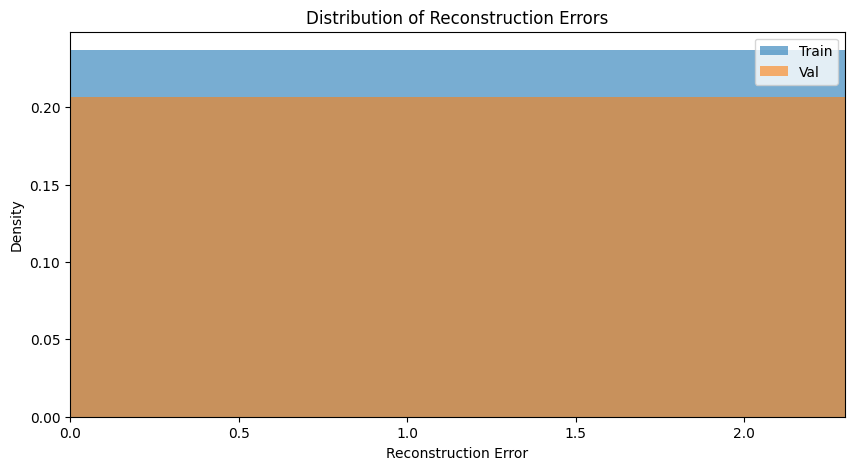

In [37]:
plt.figure(figsize=(10, 5))
plt.hist(train_errors, bins=100, alpha=0.6, label="Train", density=True)
plt.hist(val_errors, bins=100, alpha=0.6, label="Val", density=True)
plt.xlabel("Reconstruction Error")
plt.ylabel("Density")
plt.legend()
plt.title("Distribution of Reconstruction Errors")
plt.xlim(0, np.percentile(train_errors, 99))  # zoom in, ignore extreme tail for readability
plt.show()

In [38]:
print("Train errors - min:", train_errors.min(), "max:", train_errors.max())
print("Percentiles:")
for p in [50, 90, 95, 99, 99.9, 99.99]:
    print(f"  {p}th percentile: {np.percentile(train_errors, p):.4f}")

Train errors - min: 0.0009707476 max: 421.20285
Percentiles:
  50th percentile: 0.0272
  90th percentile: 0.3535
  95th percentile: 0.8028
  99th percentile: 2.2987
  99.9th percentile: 5.7605
  99.99th percentile: 29.2259


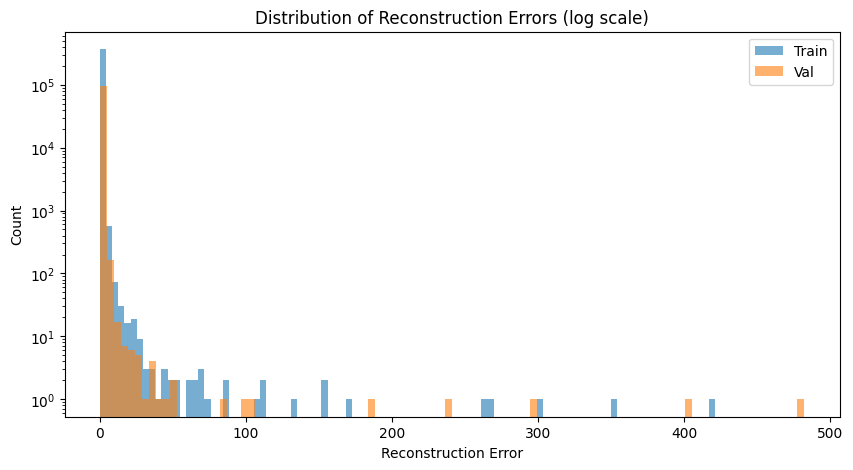

In [39]:
plt.figure(figsize=(10, 5))
plt.hist(train_errors, bins=100, alpha=0.6, label="Train")
plt.hist(val_errors, bins=100, alpha=0.6, label="Val")
plt.xlabel("Reconstruction Error")
plt.ylabel("Count")
plt.yscale("log")
plt.legend()
plt.title("Distribution of Reconstruction Errors (log scale)")
plt.show()

In [40]:
# Choose a threshold based on percentile of TRAINING error (since training represents "normal" baseline)
THRESHOLD_PERCENTILE = 99  # flag top 1% as anomalous
threshold = np.percentile(train_errors, THRESHOLD_PERCENTILE)

print(f"Anomaly threshold (error): {threshold:.4f}")

# Apply to validation set
val_anomaly_flags = val_errors > threshold
print(f"Anomalies flagged in validation: {val_anomaly_flags.sum()} out of {len(val_errors)} ({val_anomaly_flags.mean()*100:.2f}%)")

Anomaly threshold (error): 2.2987
Anomalies flagged in validation: 1738 out of 95656 (1.82%)


In [41]:
# Get the sequences and MMSIs corresponding to validation data
val_mmsi_for_windows = seq_mmsi[val_mask]

# Find indices of the top 5 highest-error anomalies in validation
top_anomaly_indices = np.argsort(val_errors)[-5:][::-1]

for idx in top_anomaly_indices:
    print(f"\n--- Anomaly (error={val_errors[idx]:.2f}), Vessel MMSI: {val_mmsi_for_windows[idx]} ---")
    # Reverse the scaling to see real-world values
    real_values = scaler.inverse_transform(X_val[idx])
    anomaly_df = pd.DataFrame(real_values, columns=FEATURES)
    print(anomaly_df.round(2))


--- Anomaly (error=482.24), Vessel MMSI: 636093156 ---
      SOG       COG  speed_change  course_change  distance_nm  time_gap_min
0   49.29  32661.28          5.19         562.78         1.78   10034357.11
1   49.29  32923.32         -0.00          47.24         0.06        207.80
2   49.78  33054.35          0.13          25.84         0.06        207.80
3   49.29  33054.35         -0.14           4.43         0.06        181.56
4   48.81  32923.32         -0.14          25.84         0.06        207.80
5   48.81  32988.84         -0.00          15.13         0.06        207.80
6   48.32  33043.43         -0.14          13.35         0.06        204.88
7   48.32  32977.92         -0.00          15.13         0.06        204.88
8   47.84  32694.04         -0.14          50.81         0.06        213.63
9   47.84  32890.57         -0.00          36.54         0.06        207.80
10  47.84  32672.20         -0.00          40.11         0.06        207.80
11  47.84  32606.69         -0.0

In [42]:
val_mmsi_for_windows = seq_mmsi[val_mask]

top_anomaly_indices = np.argsort(val_errors)[-5:][::-1]

for idx in top_anomaly_indices:
    print(f"\n--- Anomaly (error={val_errors[idx]:.2f}), Vessel MMSI: {val_mmsi_for_windows[idx]} ---")
    anomaly_df = pd.DataFrame(X_val[idx], columns=FEATURES)  # X_val is already real units - no inverse_transform needed
    print(anomaly_df.round(2))


--- Anomaly (error=482.24), Vessel MMSI: 636093156 ---
    SOG    COG  speed_change  course_change  distance_nm  time_gap_min
0   9.7  297.2           3.9           31.3        16.60      57367.90
1   9.7  299.6           0.0            2.4         0.19          1.17
2   9.8  300.8           0.1            1.2         0.19          1.17
3   9.7  300.8          -0.1            0.0         0.16          1.02
4   9.6  299.6          -0.1            1.2         0.19          1.17
5   9.6  300.2           0.0            0.6         0.18          1.17
6   9.5  300.7          -0.1            0.5         0.19          1.15
7   9.5  300.1           0.0            0.6         0.18          1.15
8   9.4  297.5          -0.1            2.6         0.19          1.20
9   9.4  299.3           0.0            1.8         0.18          1.17
10  9.4  297.3           0.0            2.0         0.18          1.17
11  9.4  296.7           0.0            0.6         0.18          1.15
12  9.3  298.0       

In [43]:
import pickle
import os

# Create a folder to store everything
os.makedirs("saved_model", exist_ok=True)

# 1. Save the PyTorch model weights
torch.save(model.state_dict(), "saved_model/lstm_autoencoder.pth")

# 2. Save the scaler
with open("saved_model/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

# 3. Save the threshold and feature list together
metadata = {
    "threshold": float(threshold),
    "features": FEATURES,
    "window_size": WINDOW_SIZE,
    "hidden_dim": 32,
    "latent_dim": 16,
}
with open("saved_model/metadata.pkl", "wb") as f:
    pickle.dump(metadata, f)

print("Saved successfully!")
print("Files in saved_model/:", os.listdir("saved_model"))

Saved successfully!
Files in saved_model/: ['lstm_autoencoder.pth', 'metadata.pkl', 'scaler.pkl']


In [44]:
# Simulate a "fresh start" - reload everything from disk

# 1. Recreate the model architecture (must match exactly)
loaded_model = LSTMAutoencoder(n_features=6, hidden_dim=32, latent_dim=16).to(device)
loaded_model.load_state_dict(torch.load("saved_model/lstm_autoencoder.pth"))
loaded_model.eval()

# 2. Reload the scaler
with open("saved_model/scaler.pkl", "rb") as f:
    loaded_scaler = pickle.load(f)

# 3. Reload metadata
with open("saved_model/metadata.pkl", "rb") as f:
    loaded_metadata = pickle.load(f)

print("Loaded threshold:", loaded_metadata["threshold"])
print("Loaded features:", loaded_metadata["features"])

# 4. Quick sanity check - does the loaded model give the same results as the original?
test_errors_loaded = get_reconstruction_errors(loaded_model, val_loader, device)
print("\nOriginal val error mean:", val_errors.mean())
print("Loaded model val error mean:", test_errors_loaded.mean())

Loaded threshold: 2.2987420558929443
Loaded features: ['SOG', 'COG', 'speed_change', 'course_change', 'distance_nm', 'time_gap_min']

Original val error mean: 0.2457671
Loaded model val error mean: 0.2457671


In [45]:
# Simulate a vessel cruising steadily - should get LOW anomaly score
normal_sequence = pd.DataFrame({
    "SOG": [10.0]*20,
    "COG": [180.0]*20,
    "speed_change": [0.0]*20,
    "course_change": [0.0]*20,
    "distance_nm": [0.17]*20,
    "time_gap_min": [1.0]*20,
})

# Scale it using our saved scaler, then run through the model
normal_scaled = loaded_scaler.transform(normal_sequence[FEATURES].values)
normal_tensor = torch.tensor(normal_scaled, dtype=torch.float32).unsqueeze(0).to(device)

with torch.no_grad():
    reconstruction = loaded_model(normal_tensor)
    error = ((reconstruction - normal_tensor) ** 2).mean().item()

print(f"Normal sequence error: {error:.4f}")
print(f"Threshold: {loaded_metadata['threshold']:.4f}")
print(f"Flagged as anomaly? {error > loaded_metadata['threshold']}")

Normal sequence error: 0.0064
Threshold: 2.2987
Flagged as anomaly? False


In [46]:
# Simulate: cruising normally, then a huge time gap, then erratic movement
anomaly_sequence = pd.DataFrame({
    "SOG":           [10.0]*10 + [0.0, 25.0, 3.0, 40.0, 1.0, 30.0, 5.0, 0.0, 35.0, 2.0],
    "COG":           [180.0]*10 + [45.0, 270.0, 10.0, 300.0, 90.0, 200.0, 15.0, 330.0, 60.0, 250.0],
    "speed_change":  [0.0]*10 + [-10.0, 25.0, -22.0, 37.0, -39.0, 29.0, -25.0, -5.0, 35.0, -33.0],
    "course_change": [0.0]*10 + [135.0, 180.0, 100.0, 150.0, 170.0, 110.0, 175.0, 160.0, 130.0, 170.0],
    "distance_nm":   [0.17]*10 + [5.0, 8.0, 0.5, 12.0, 0.2, 9.0, 1.0, 0.1, 15.0, 0.3],
    "time_gap_min":  [1.0]*9 + [5000.0] + [1.0]*10,
})

anomaly_scaled = loaded_scaler.transform(anomaly_sequence[FEATURES].values)
anomaly_tensor = torch.tensor(anomaly_scaled, dtype=torch.float32).unsqueeze(0).to(device)

with torch.no_grad():
    reconstruction = loaded_model(anomaly_tensor)
    error = ((reconstruction - anomaly_tensor) ** 2).mean().item()

print(f"Anomalous sequence error: {error:.4f}")
print(f"Threshold: {loaded_metadata['threshold']:.4f}")
print(f"Flagged as anomaly? {error > loaded_metadata['threshold']}")

Anomalous sequence error: 461.8900
Threshold: 2.2987
Flagged as anomaly? True
